In [12]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
from sparse_recov import perform_least_squares_fit, add_fit_lines_to_plot, plot_on_facets
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport


In [ ]:
df= pd.read_pickle("../data/jan_2025_30.pickle")
# df= pd.read_pickle("../dataylastdf.pickle")
profile = ProfileReport(df, title="Profiling Report")
profile.to_notebook_iframe()

EOFError: Ran out of input

In [ ]:
thetime = df['runtime_seconds'].describe()
print(thetime.mean())
(15*60)/thetime.mean() 

7.0165302460278784


np.float64(128.26852709848976)

In [ ]:
df_vals(df)

'm':
[   100 262144]
----------------------------------------
'k':
[100]
----------------------------------------
'sigma':
[1.]
----------------------------------------
'img':
Categorical:  ['camera']
Categories (2, object): ['phantom', 'camera']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'alg':
- bpdn_projected
----------------------------------------
'seed':
[ 822569775 2137449171 2671936806 3512589365 1880026316 2629000564]
----------------------------------------
're':
[       nan 0.00254133 0.00254176 0.00269923]
----------------------------------------
'runtime_seconds':
[        nan  6.53382635 12.50094557  6.23688507]
----------------------------------------
'indices':
unhashable type: 'numpy.ndarray'
----------------------------------------
'experiment_fn_label':
- nan
- uneven_on_exactly_sparse


In [ ]:
mydf = df[(df['adapted_sampling']==True)&(df['alg']=='bpdn_projected')]

fit_df = perform_least_squares_fit(
    mydf[mydf['sigma'] > 1e-3],
    x_col='m',
    y_col='re',
    group_cols=['k', 'sigma', 'alg', 'img', 'sampling_type', 'adapted_sampling'],
    min_x=10**3.2
)


# Create the main plot
g = sns.relplot(
    data=mydf,
    kind="line",
    x="m",
    y="re",
    col = 'k',
    palette="plasma",
    hue="sigma",
    hue_norm=LogNorm(vmin=1e-4, clip=True),
    errorbar="se"
)

g.set(xscale="log", yscale="log")

plot_on_facets(add_fit_lines_to_plot, g, fit_df, col_label="k", row_label="alg")

plt.show()


/Users/matthewscott/Prog/Sparse_adapted_denoising/sparse_recov/sampling_recov_functions.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = df_filtered.groupby(group_cols)


ValueError: Cannot calculate a linear regression if all x values are identical

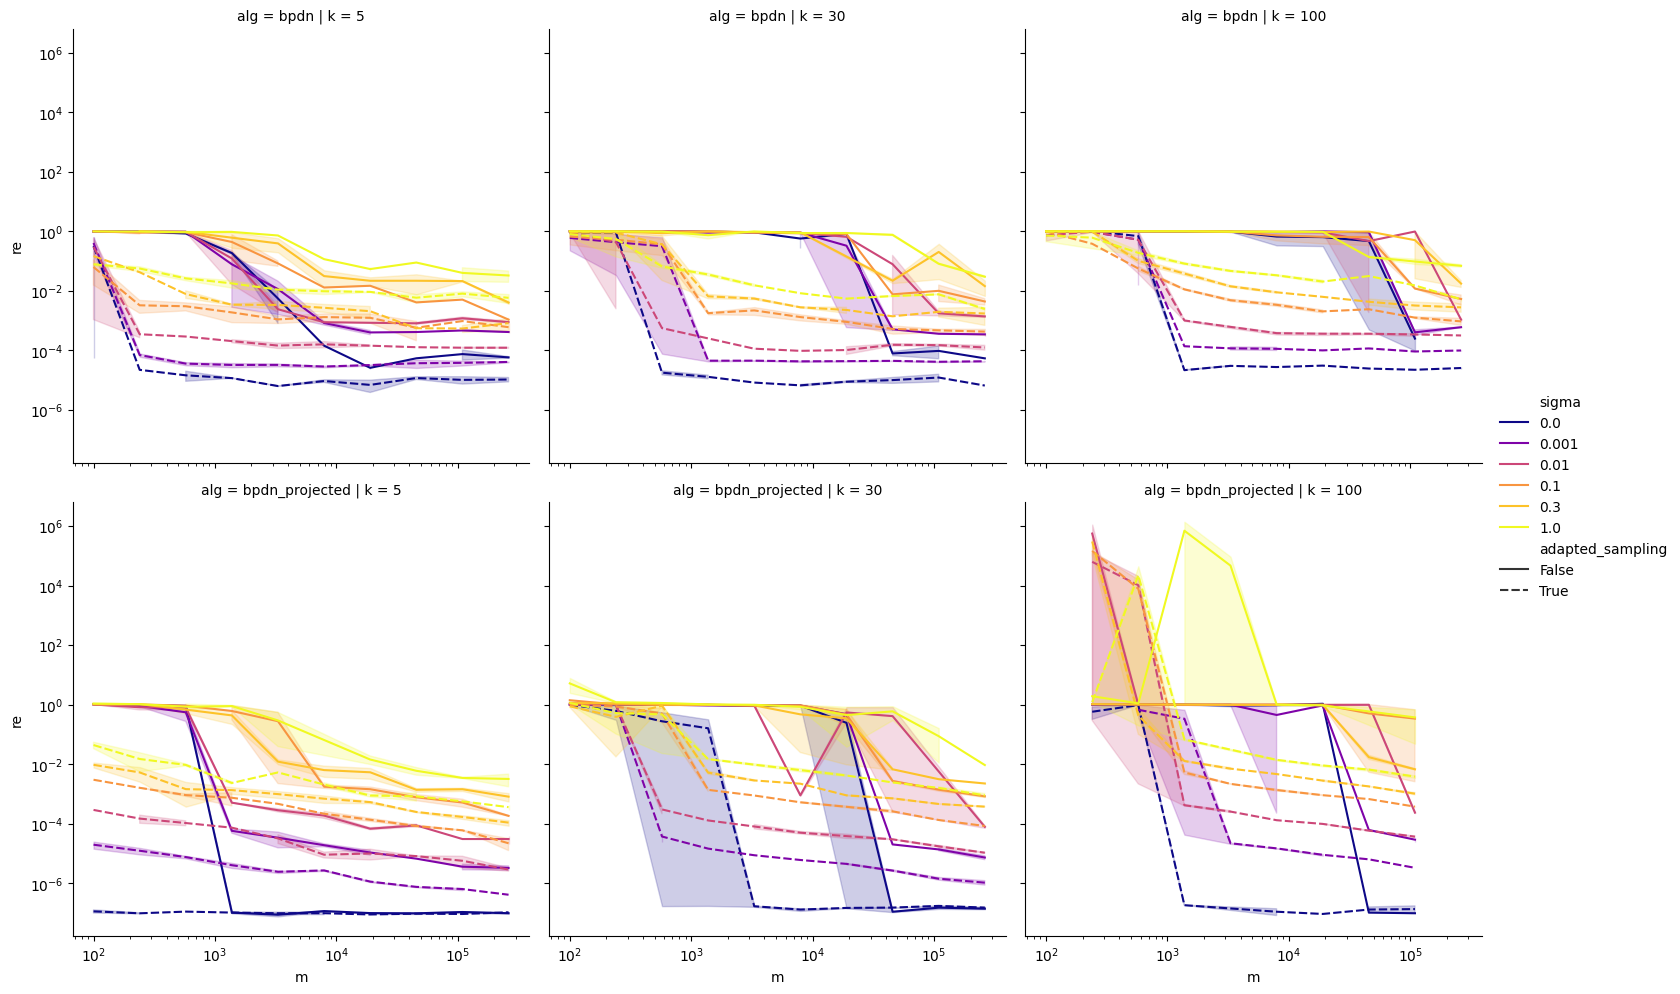

In [ ]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
# doubledf = melt_and_keep(df, ["re","emp_snr"])
# g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False}
%matplotlib inline
sns.relplot(df, kind = "line", x = "m", y="re", row="alg", style="adapted_sampling", col='k',  hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
# for ax in g.axes.flat:
#     ax.set_yscale('log')  # Set y-axis to log scale
plt.yscale('log')  # Set y-axis to log scale
plt.xscale("log")
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

In [ ]:
melt_and_keep(df, ["re","emp_snr"]).columns

Index(['m', 'k', 'sigma', 'img', 'sampling_type', 'adapted_sampling',
       'preconditionned_optimization', 'alg', 'seed', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'noise_mag', 'signal_mag',
       'ERROR', 'variable', 'value'],
      dtype='object')

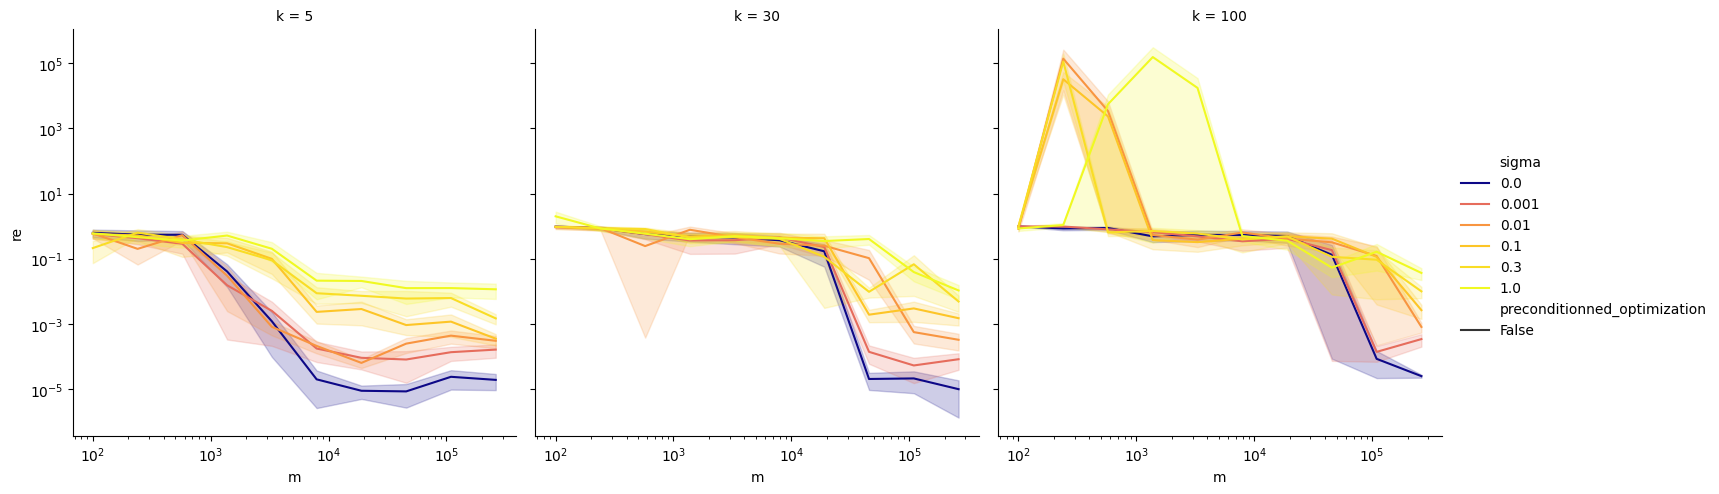

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="re", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale("log")
plt.yscale("log")

In [ ]:
%matplotlib inline
g = sns.relplot(doubledf, kind = "line", x = "m", y="value", col="k", row="variable", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

NameError: name 'doubledf' is not defined

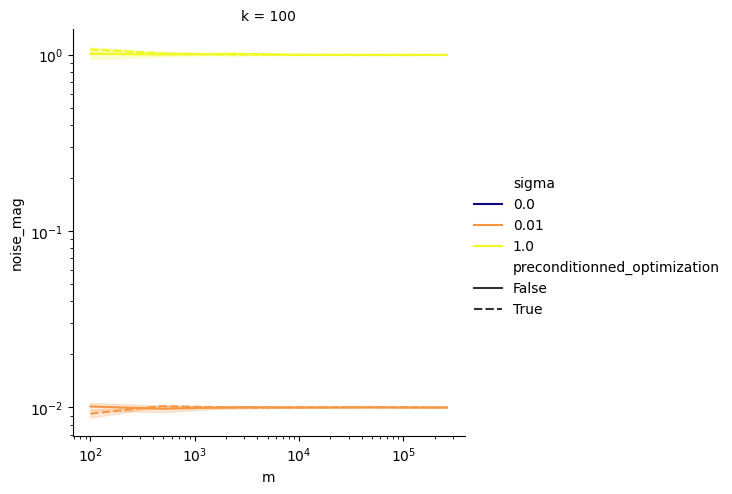

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="noise_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

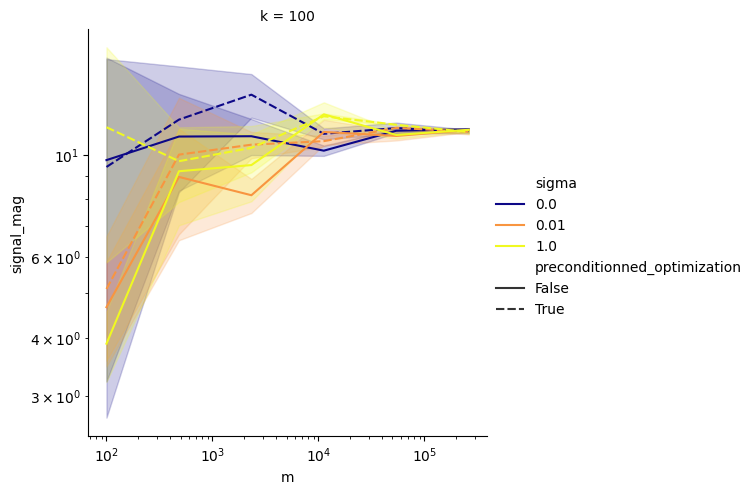

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="signal_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

In [ ]:
kkjdf_wr

NameError: name 'kkjdf_wr' is not defined